In [ ]:
# Import bibliotek python
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [ ]:
# Połączenie google colab z dyskiem google
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [ ]:
# Import danych z dysku do google colab
from typing import Final
%cd /content/drive/MyDrive/colab mate/Final_project

/content/drive/MyDrive/colab mate/Final_project


In [ ]:
# Wczytanie plików CSV z dysku google
events = pd.read_csv('events.csv')
products = pd.read_csv('products.csv')
countries = pd.read_csv('countries.csv')


In [ ]:
# Sprawdzenie zawartosci tabeli Events
events.head()

,Order ID,Order Date,Ship Date,Order Priority,Country Code,Product ID,Sales Channel,Units Sold,Unit Price,Unit Cost
0,100640618,10/8/2014,10/18/2014,M,NOR,2103,Online,650.0,205.70,117.11
1,100983083,8/11/2016,8/11/2016,C,SRB,2103,Offline,1993.0,205.70,117.11
2,101025998,7/18/2014,8/11/2014,M,NaN,7940,Online,4693.0,668.27,502.54
3,102230632,5/13/2017,6/13/2017,L,MNE,2455,Online,1171.0,109.28,35.84
4,103435266,8/11/2012,9/18/2012,H,SRB,1270,Offline,7648.0,47.45,31.79


In [ ]:
# Zmiana formatu daty w pliku Events
events['Order Date'] = pd.to_datetime(events['Order Date'])
events['Ship Date'] = pd.to_datetime(events['Ship Date'])

In [ ]:
# Sprawdzenie typów danych w tabeli Events
events.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1330 entries, 0 to 1329
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   Order ID        1330 non-null   int64         
 1   Order Date      1330 non-null   datetime64[ns]
 2   Ship Date       1330 non-null   datetime64[ns]
 3   Order Priority  1330 non-null   object        
 4   Country Code    1248 non-null   object        
 5   Product ID      1330 non-null   int64         
 6   Sales Channel   1330 non-null   object        
 7   Units Sold      1328 non-null   float64       
 8   Unit Price      1330 non-null   float64       
 9   Unit Cost       1330 non-null   float64       
dtypes: datetime64[ns](2), float64(3), int64(2), object(3)
memory usage: 104.0+ KB


In [ ]:
# #sprawdzenie zawartosci tabeli Products
products.head()

,id,item_type
0,2103,Cereal
1,7940,Household
2,2455,Clothes
3,1270,Beverages
4,8681,Office Supplies


In [ ]:
# Sprawdzenie typów danych w tabeli Products
products.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12 entries, 0 to 11
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   id         12 non-null     int64 
 1   item_type  12 non-null     object
dtypes: int64(1), object(1)
memory usage: 324.0+ bytes


In [ ]:
countries = countries.rename(columns={'alpha-3': 'Country Code', 'alpha-2': 'Country Code 2'})


In [ ]:
#Podglad tabeli Countries
countries.head()

,name,Country Code 2,Country Code,region,sub-region
0,Afghanistan,AF,AFG,Asia,Southern Asia
1,Åland Islands,AX,ALA,Europe,Northern Europe
2,Albania,AL,ALB,Europe,Southern Europe
3,Algeria,DZ,DZA,Africa,Northern Africa
4,American Samoa,AS,ASM,Oceania,Polynesia


In [ ]:
# Sprawdzenie typów danych w tabeli Countries
countries.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 249 entries, 0 to 248
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   name            249 non-null    object
 1   Country Code 2  248 non-null    object
 2   Country Code    249 non-null    object
 3   region          248 non-null    object
 4   sub-region      248 non-null    object
dtypes: object(5)
memory usage: 9.9+ KB


In [ ]:
# Policzenie ile wystepuje postych komórek w tabelach Events, Products, Countries
print(events.isna().sum())
print(events.isna().mean() * 100)
print(products.isna().sum())
print(countries.isna().sum())

Order ID           0
Order Date         0
Ship Date          0
Order Priority     0
Country Code      82
Product ID         0
Sales Channel      0
Units Sold         2
Unit Price         0
Unit Cost          0
dtype: int64
Order ID          0.000000
Order Date        0.000000
Ship Date         0.000000
Order Priority    0.000000
Country Code      6.165414
Product ID        0.000000
Sales Channel     0.000000
Units Sold        0.150376
Unit Price        0.000000
Unit Cost         0.000000
dtype: float64
id           0
item_type    0
dtype: int64
name              0
Country Code 2    1
Country Code      0
region            1
sub-region        1
dtype: int64


In [ ]:
# Usuniecie wierszy zawierajacych puste komorki 'Country Code', Units Sold'
events= events.dropna(subset = 'Units Sold')
countries= countries.dropna(subset = 'Country Code 2')
countries= countries.dropna(subset = 'region')
countries= countries.dropna(subset = 'sub-region')
events= events.dropna(subset = 'Country Code')
events= events.dropna(subset = 'Units Sold')
countries= countries.dropna(subset = 'Country Code 2')
countries= countries.dropna(subset = 'region')
countries= countries.dropna(subset = 'sub-region')

In [ ]:
# Ponowne sprawdzenie czy wystepuja puste komorki w tabelach
print(events.isna().sum())
print(events.isna().mean() * 100)
print(products.isna().sum())
print(countries.isna().sum())

Order ID          0
Order Date        0
Ship Date         0
Order Priority    0
Country Code      0
Product ID        0
Sales Channel     0
Units Sold        0
Unit Price        0
Unit Cost         0
dtype: int64
Order ID          0.0
Order Date        0.0
Ship Date         0.0
Order Priority    0.0
Country Code      0.0
Product ID        0.0
Sales Channel     0.0
Units Sold        0.0
Unit Price        0.0
Unit Cost         0.0
dtype: float64
id           0
item_type    0
dtype: int64
name              0
Country Code 2    0
Country Code      0
region            0
sub-region        0
dtype: int64


In [ ]:
# Sprawdzenie czy w tabelach Events, Products, Countires wystepuja wartosci zduplikowane
print(events.duplicated().sum())
print(products.duplicated().sum())
print(countries.duplicated().sum())

0
0
0


In [ ]:
# Połączenie tabeli events z tabelą products (po ID produktu) oraz tabelą countries (po kodzie kraju)
connected_table = events.merge(products, left_on='Product ID', right_on='id', how='left') \
                        .merge(countries, on='Country Code', how='left')

# Zmiana nazw kolumn tak, aby zaczynały się od wielkiej litery
connected_table.columns = connected_table.columns.str.title()

# Formatowanie wartości tekstowych w kolumnach typu 'object' na styl nazw własnych (Title Case)
for col in connected_table.columns:
    if connected_table[col].dtype == 'object':
        connected_table[col] = connected_table[col].str.title()

# Zamiana podkreślników na spacje w nazwach kolumn
connected_table.columns = connected_table.columns.str.replace('_', ' ')

# Zmiana nazwy kolumny 'Name' na bardziej czytelną 'Country'
connected_table.columns = connected_table.columns.str.replace('Name', 'Country')

# Usunięcie zbędnej kolumny 'Country Code 2', jeśli istnieje
connected_table.drop(columns=['Country Code 2'], inplace=True, errors='ignore')

# Wyświetlenie gotowej tabeli
connected_table

,Order Id,Order Date,Ship Date,Order Priority,Country Code,Product Id,Sales Channel,Units Sold,Unit Price,Unit Cost,Id,Item Type,Country,Region,Sub-Region
0,100640618,2014-10-08,2014-10-18,M,Nor,2103,Online,650.0,205.70,117.11,2103,Cereal,Norway,Europe,Northern Europe
1,100983083,2016-08-11,2016-08-11,C,Srb,2103,Offline,1993.0,205.70,117.11,2103,Cereal,Serbia,Europe,Southern Europe
2,102230632,2017-05-13,2017-06-13,L,Mne,2455,Online,1171.0,109.28,35.84,2455,Clothes,Montenegro,Europe,Southern Europe
3,103435266,2012-08-11,2012-09-18,H,Srb,1270,Offline,7648.0,47.45,31.79,1270,Beverages,Serbia,Europe,Southern Europe
4,103450715,2015-03-15,2015-04-18,H,Svk,8681,Online,2220.0,651.21,524.96,8681,Office Supplies,Slovakia,Europe,Eastern Europe
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1241,994504153,2017-01-10,2017-01-13,M,Swe,4594,Online,4734.0,9.33,6.92,4594,Fruits,Sweden,Europe,Northern Europe
1242,994978797,2014-12-05,2015-01-02,H,Ita,1270,Offline,5192.0,47.45,31.79,1270,Beverages,Italy,Europe,Southern Europe
1243,996754205,2010-09-20,2010-09-22,L,Rus,7331,Offline,574.0,255.28,159.42,7331,Baby Food,Russia,Europe,Eastern Europe
1244,998043382,2010-06-15,2010-07-03,H,Mlt,8293,Online,2070.0,437.20,263.33,8293,Cosmetics,Malta,Europe,Southern Europe


In [ ]:
# Obliczenie róznicy miedzy data zamówienia a data wysyłki dodanie nowej kolumny 'ship_days', a nastepnie wyswietlenie podstawowej statystki opisowej nowej kolumny
connected_table['ship_days'] = (connected_table['Ship Date'] - connected_table['Order Date']).dt.days
print(connected_table['ship_days'].describe())

count    1246.000000
mean       24.875602
std        14.622855
min         0.000000
25%        12.000000
50%        25.000000
75%        37.000000
max        50.000000
Name: ship_days, dtype: float64


In [ ]:
# Sprawdzenie najdłuższego czasu wysłki
max= connected_table['ship_days'].value_counts().max()
# Sprawdzenie najkrutszego czasu wysłki
min= connected_table['ship_days'].value_counts().min()
print(f'Max: {max}')
print(f'Min: {min}')

Max: 34
Min: 15


In [ ]:
# Policzenie kluczowych wskaźnikow: Całkowity zysk, Całkowita liczba zamówień, Liczba kraj które zamowily produkty
total_country = connected_table['Country'].nunique()
total_order = connected_table['Order Id'].nunique()
connected_table['total_profit'] = (connected_table['Unit Price'] - connected_table['Unit Cost']) * connected_table['Units Sold']
total_profit = connected_table['total_profit'].sum()
print(f'Total profit: {total_profit}')
print(f'Total number of orders: {total_order}')
print(f'Total number of countries: {total_country}')

Total profit: 473709035.06
Total number of orders: 1246
Total number of countries: 45


In [ ]:
# Obliczenie liczby wykonanych zamówień online oraz offline
Sales_Channel_total = connected_table['Sales Channel'].value_counts()
Sales_Channel_total

,count
Sales Channel,
Online,625
Offline,621


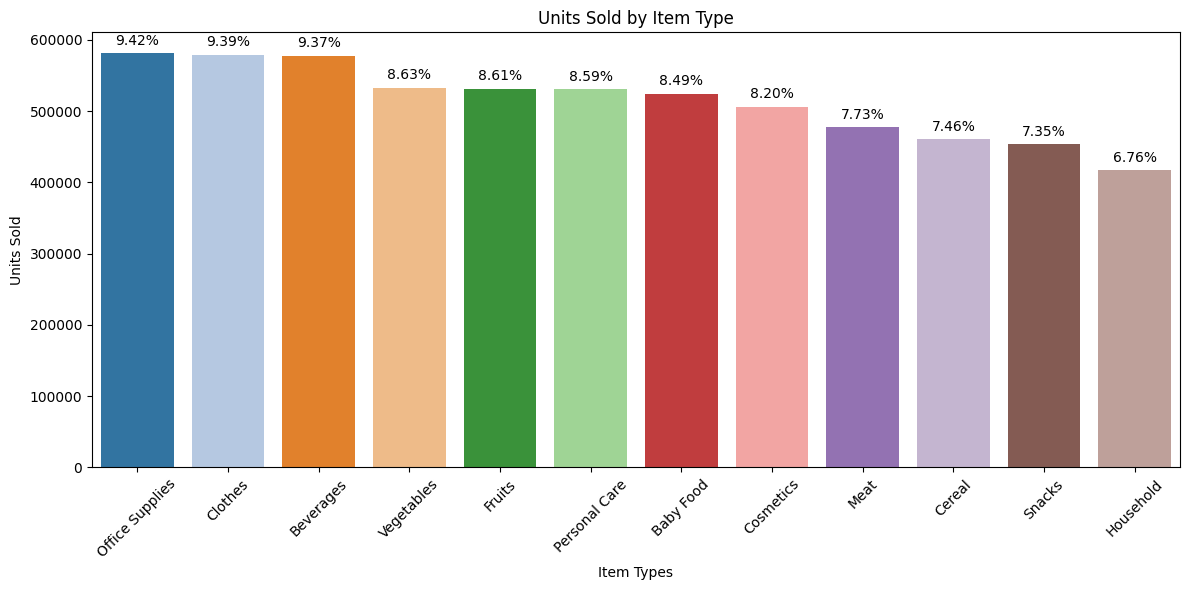

In [ ]:
# Agregacja danych: sumowanie sprzedanych jednostek dla każdego typu produktu
sales_data = connected_table.groupby('Item Type', as_index=False)['Units Sold'].sum()

# Obliczenie całkowitej liczby sprzedanych jednostek
Units_Sold_total = connected_table['Units Sold'].sum()

# Obliczenie procentowego udziału każdej kategorii w całkowitej sprzedaży
sales_data['Units Sold %'] = (sales_data['Units Sold'] / Units_Sold_total) * 100

# Sortowanie danych malejąco według liczby sprzedanych jednostek
sales_data = sales_data.sort_values(by='Units Sold', ascending=False)

# Inicjalizacja wykresu słupkowego
plt.figure(figsize=(12, 6))
ax = sns.barplot(data=sales_data, x='Item Type', y='Units Sold', hue='Item Type', palette='tab20', legend=False)

# Dodawanie etykiet procentowych nad każdym słupkiem
for p in ax.patches:
    percentage = (p.get_height() / Units_Sold_total) * 100
    ax.annotate(f'{percentage:.2f}%',
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center',
                xytext=(0, 9),
                textcoords='offset points')

# Konfiguracja osi, rotacja etykiet i tytuł wykresu
plt.xticks(rotation=45)
plt.xlabel('Item Types')
plt.ylabel('Units Sold')
plt.title('Units Sold by Item Type')

# Dopasowanie układu i wyświetlenie wykresu
plt.tight_layout()
plt.show()

### Analiza wykresu 'Units Sold by Item Type'

Na podstawie wykresu oraz danych sprzedażowych można wyciągnąć następujące wnioski:

1. **Najlepiej sprzedające się produkty**: Liderami pod względem liczby sprzedanych jednostek są kategorie **Office Supplies (Materiały biurowe)**, **Clothes (Odzież)** oraz **Beverages (Napoje)**. To one generują największy ruch w Twoim sklepie.
2. **Kategorie o średniej sprzedaży**: Produkty takie jak **Fruits**, **Vegetables** czy **Personal Care** utrzymują się w środku stawki, stanowiąc istotne uzupełnienie oferty.
3. **Najsłabsze kategorie**: Najmniejszą popularnością cieszą się produkty z kategorii **Snacks**, **Household** oraz **Cereal**, która znajduje się w dolnej trójce zestawienia.
4. **Wniosek**: Twoja sprzedaż opiera się głównie na materiałach biurowych i odzieży. Znacznie słabszy wynik kategorii spożywczych (jak napoje vs płatki) sugeruje, że preferencje klientów są mocno ukierunkowane na konkretne grupy asortymentowe.

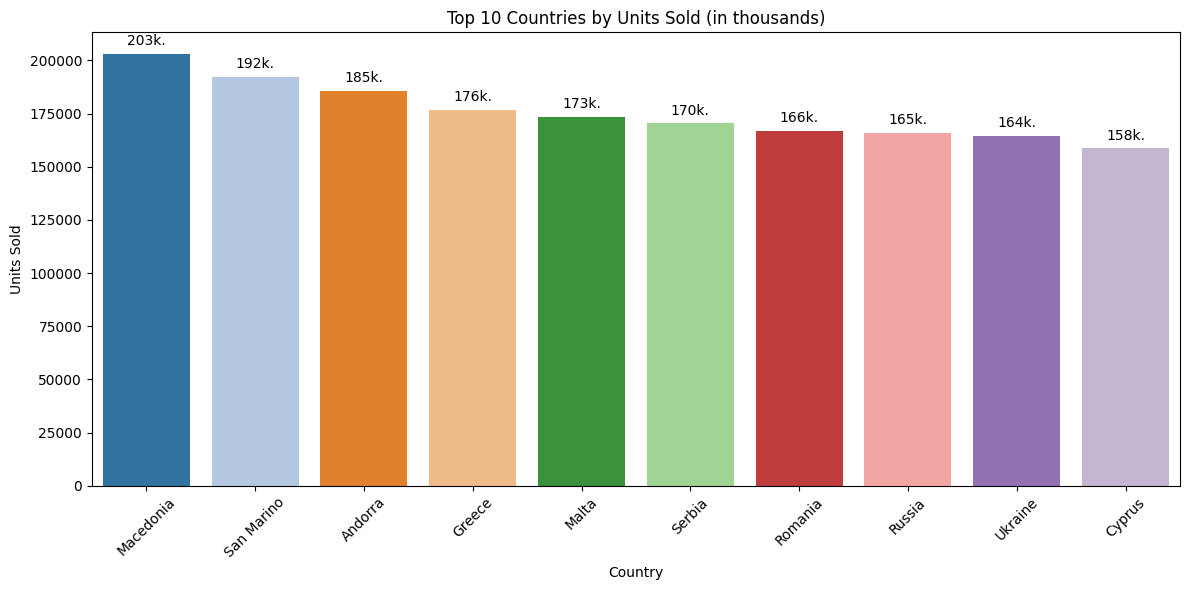

In [ ]:
# Agregacja danych: sumowanie Units Sold dla każdego kraju
sales_data = connected_table.groupby('Country', as_index=False)['Units Sold'].sum()

# Wybór 10 krajów z najwyższym wynikiem sprzedaży
sales_data = sales_data.sort_values(by='Units Sold', ascending=False).head(10)

# Ustawienie rozmiaru wykresu
plt.figure(figsize=(12, 6))

# Generowanie wykresu słupkowego
ax = sns.barplot(data=sales_data, x='Country', y='Units Sold', hue='Country', palette='tab20', legend=False)

# Dodawanie wartości liczbowych nad słupkami (w tysiącach 'k')
for p in ax.patches:
    if p.get_height() > 0:
        ax.annotate(f'{int(p.get_height()/1000)}k.',
                    (p.get_x() + p.get_width() / 2., p.get_height()),
                    ha='center', va='center',
                    xytext=(0, 9),
                    textcoords='offset points')

# Formatowanie osi oraz tytułu
plt.xticks(rotation=45)
plt.xlabel('Country')
plt.ylabel('Units Sold')
plt.title('Top 10 Countries by Units Sold (in thousands)')

# Automatyczne dopasowanie i wyświetlenie
plt.tight_layout()
plt.show()

**Analiza wykres 'Top 10 Countries by Units Sold'**
1. Liderzy zestawienia: Macedonia oraz San Marino dominują w rankingu, osiągając odpowiednio poziom około 203 tys. oraz 192 tys. sprzedanych jednostek. Są to kluczowe rynki pod względem wolumenu sprzedaży.
2. Stabilna czołówka: Kraje z miejsc 3-6 (Andora, Grecja, Malta, Serbia) wykazują bardzo zbliżone wyniki, oscylujące w granicach 170-186 tys. jednostek. Świadczy to o wyrównanym i stabilnym popycie w tych regionach.
3. Dominacja rynków europejskich: Warto zauważyć, że cała pierwsza dziesiątka składa się z krajów europejskich (m.in. Ukraina, Cypr, Mołdawia, Rosja), co potwierdza, że Europa jest głównym motorem napędowym sprzedaży ilościowej w Twoim zbiorze danych.

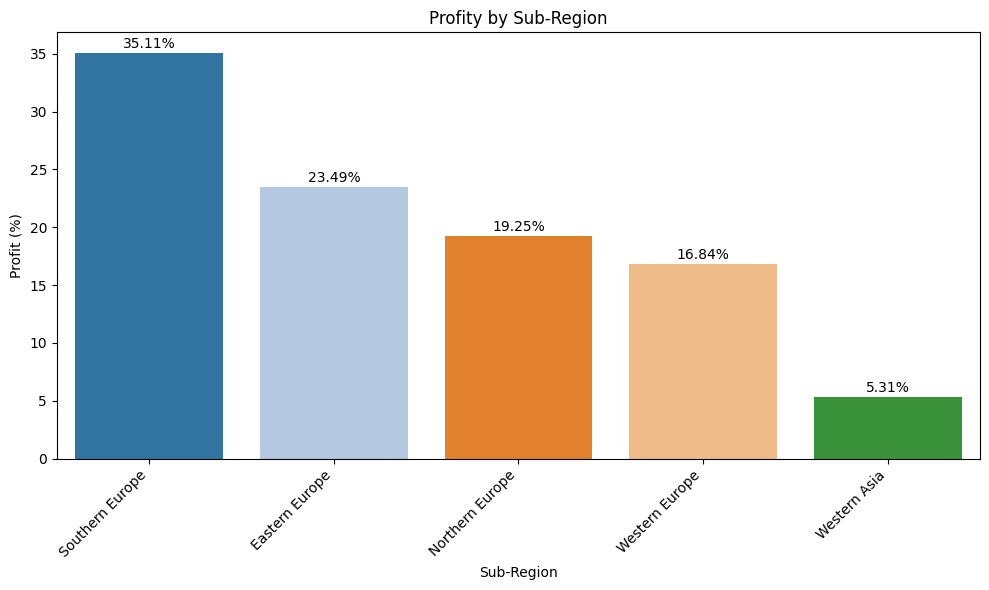

In [ ]:
# Grupowanie danych według subregionu i sumowanie zysku całkowitego
profit_by_subregion = connected_table.groupby('Sub-Region')['total_profit'].sum().reset_index()

# Obliczenie sumy zysków dla wszystkich regionów
grand_total_profit = profit_by_subregion['total_profit'].sum()

# Obliczenie procentowego udziału każdego subregionu w zysku całkowitym
profit_by_subregion['profit_pct'] = (profit_by_subregion['total_profit'] / grand_total_profit) * 100

# Sortowanie danych malejąco według udziału procentowego
profit_by_subregion = profit_by_subregion.sort_values(by='profit_pct', ascending=False)

# Inicjalizacja wykresu słupkowego
plt.figure(figsize=(10, 6))
ax = sns.barplot(data=profit_by_subregion, x='Sub-Region', y='profit_pct', hue='Sub-Region', palette='tab20', legend=False)

# Dodanie etykiet z wartościami procentowymi nad słupkami
for container in ax.containers:
    ax.bar_label(container, fmt='%.2f%%', padding=1.5)

# Konfiguracja osi, rotacja etykiet dla lepszej czytelności i tytuł
plt.xticks(rotation=45, ha='right')
plt.xlabel('Sub-Region')
plt.ylabel('Profit (%)')
plt.title('Profity by Sub-Region')

# Wyświetlenie gotowego wykresu
plt.tight_layout()
plt.show()

**Analiza wykres 'Profity by Sub-Region'**
1. **Dominacja Europy Południowej**: Ten subregion generuje największą część całkowitego zysku – aż 35,11%. Jest to kluczowy obszar dla rentowności działalności.
2. **Silna pozycja Europy Wschodniej i Północnej**: Te dwa regiony łącznie odpowiadają za blisko 43% zysków (odpowiednio 23,49% i 19,25%). Europa jako całość jest zdecydowanie najbardziej dochodowym rynkiem w tym zestawieniu.
3. **Europa Zachodnia**: Mimo że jest to rozwinięty rynek, generuje 16,84% zysku, co plasuje go na czwartym miejscu. Warto przeanalizować, czy wynika to z mniejszej liczby zamówień, czy może z wyższych kosztów operacyjnych w tym regionie.
4. **Niska rentowność Azji Zachodniej**: Subregion ten odpowiada jedynie za 5,31% całkowitego zysku. Jest to obszar o najmniejszym wpływie na wynik finansowy, co może sugerować potrzebę rewizji strategii sprzedaży lub logistyki na tym rynku.


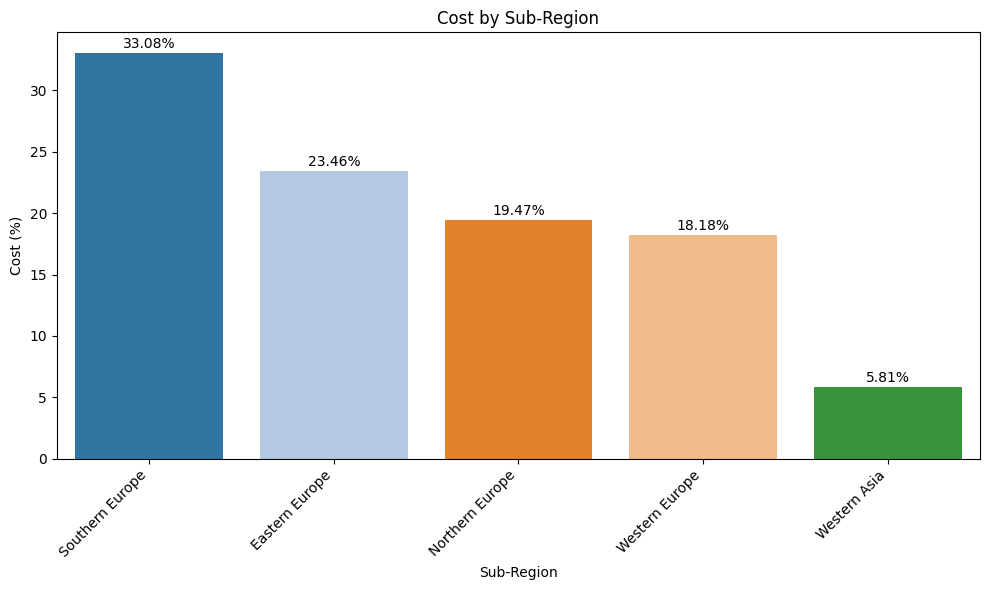

In [ ]:
# Agregacja danych: sumowanie kosztów jednostkowych (Unit Cost) dla każdego subregionu
cost_by_subregion = connected_table.groupby('Sub-Region')['Unit Cost'].sum().reset_index()

# Obliczenie całkowitej sumy kosztów dla wszystkich regionów
grand_total_cost = cost_by_subregion['Unit Cost'].sum()

# Obliczenie procentowego udziału każdego subregionu w całkowitych kosztach
cost_by_subregion['cost_pct'] = (cost_by_subregion['Unit Cost'] / grand_total_cost) * 100

# Sortowanie danych malejąco według udziału procentowego
cost_by_subregion = cost_by_subregion.sort_values(by='cost_pct', ascending=False)

# Inicjalizacja wykresu słupkowego
plt.figure(figsize=(10, 6))
ax = sns.barplot(data=cost_by_subregion, x='Sub-Region', y='cost_pct', hue='Sub-Region', palette='tab20', legend=False)

# Dodanie etykiet z wartościami procentowymi nad słupkami
for container in ax.containers:
    ax.bar_label(container, fmt='%.2f%%', padding=1.5)

# Konfiguracja osi, obrót etykiet dla lepszej czytelności oraz tytuł
plt.xticks(rotation=45, ha='right')
plt.xlabel('Sub-Region')
plt.ylabel('Cost (%)')
plt.title('Cost by Sub-Region')

# Automatyczne dopasowanie i wyświetlenie wykresu
plt.tight_layout()
plt.show()

** Analiza wykres 'Cost by Sub-Region'**
1. **Struktura kosztów a zyski**: Najwyższe koszty generuje Europa Południowa (33,08%), co bezpośrednio koreluje z faktem, że jest to również najbardziej dochodowy region. Oznacza to, że wysokie nakłady w tym regionie przekładają się na największą skalę operacyjną.
2. **Efektywność kosztowa Europy Wschodniej i Północnej**: Regiony te generują odpowiednio 23,46% oraz 19,47% kosztów całkowitych. Proporcja kosztów do zysków wydaje się tu bardzo stabilna, co świadczy o przewidywalności tych rynków.
3. **Koszty w Europie Zachodniej**: Region ten odpowiada za 18,18% kosztów jednostkowych. Warto zwrócić uwagę, że udział w kosztach (18,18%) jest nieco wyższy niż udział w zyskach (16,84%), co może sugerować niższą rentowność operacyjną lub wyższe ceny zakupu towarów w tym regionie.
4. **Najniższe nakłady w Azji Zachodniej**: Zgodnie z niskim wolumenem sprzedaży, region ten generuje tylko 5,81% kosztów. Jest to rynek o najmniejszym obciążeniu dla budżetu zakupowego firmy.

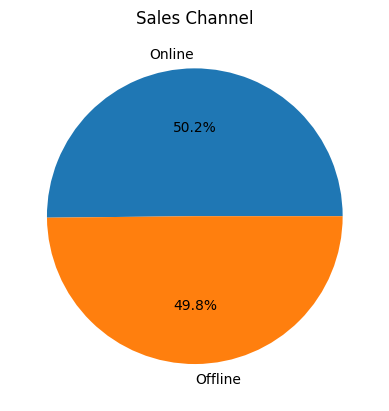

In [ ]:
# Zliczenie liczby wystąpień dla każdego kanału sprzedaży (Online/Offline)
Sales_Channel = connected_table['Sales Channel'].value_counts()

# Obliczenie całkowitej liczby wszystkich zamówień
Sales_Channel_total = Sales_Channel.sum()

# Obliczenie procentowego udziału każdego kanału w całości sprzedaży
Sales_Channel_pct = (Sales_Channel / Sales_Channel_total) * 100

# Sortowanie wyników malejąco według udziału procentowego
Sales_Channel_pct = Sales_Channel_pct.sort_values(ascending=False)

# Tworzenie wykresu kołowego z etykietami i formatowaniem procentowym (jeden znak po przecinku)
plt.pie(Sales_Channel_pct, labels=Sales_Channel.index, autopct='%1.1f%%')

# Ustawienie tytułu wykresu
plt.title('Sales Channel')

# Wyświetlenie wykresu
plt.show()

**Analiza wykresu 'Sales Channel'**
1. Na podstawie wykresy mozna stwierdzić ze liczba zrobionych zakupów online i offline jest praktycznie taka sama, zakopów online jest robionych wiecej o 0.4% w stosunku do zakupów offline

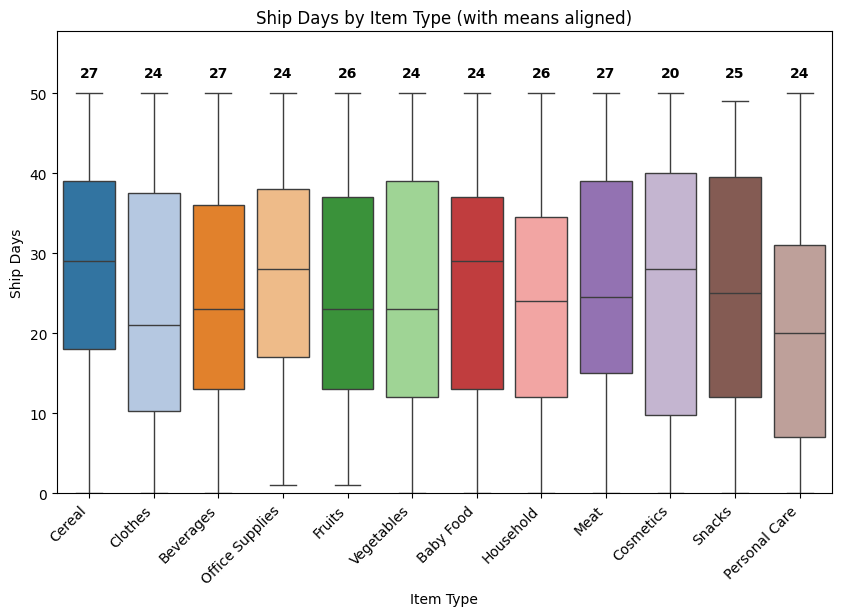

In [ ]:
# Obliczenie liczby dni wysyłki
connected_table['ship_days'] = (connected_table['Ship Date'] - connected_table['Order Date']).dt.days

# Obliczenie średniej liczby dni wysyłki dla każdej kategorii produktu
means = connected_table.groupby('Item Type')['ship_days'].mean()
Items_Type = means.index

# Inicjalizacja wykresu pudełkowego (boxplot)
plt.figure(figsize=(10, 6))
ax = sns.boxplot(data=connected_table, x='Item Type', y='ship_days', hue='Item Type', palette='tab20', legend=False)

# Ustalenie stałej wysokości dla etykiet tekstowych (5% powyżej maksymalnej wartości dni)
label_height = connected_table['ship_days'].max() * 1.05

# Pętla dodająca średnie wartości nad każdym pudełkiem
for i, item in enumerate(Items_Type):
    mean_val = means[item]
    # Wyświetlenie średniej na stałej wysokości 'label_height' dla równego wyrównania
    ax.text(i, label_height, f'{mean_val:.0f}', ha='center', va='center', fontweight='bold', color='black')

# Konfiguracja opisów osi i tytułu
plt.xlabel('Item Type')
plt.ylabel('Ship Days')
plt.title('Ship Days by Item Type (with means aligned)')
plt.xticks(rotation=45, ha='right')

# Zwiększenie limitu osi Y, aby etykiety tekstowe nie zostały przycięte
plt.ylim(0, label_height * 1.1)

# Wyświetlenie wykresu
plt.show()

** Analiza wykresu Ship Days by Item Type**
1. Średni czas oczekiwania: Średni czas od złożenia zamówienia do wysyłki (oznaczony liczbami na wykresie) jest bardzo zbliżony dla wszystkich kategorii i wynosi około 25 dni. Sugeruje to, że proces logistyczny jest ustandaryzowany i nie zależy od rodzaju asortymentu.
2. Rozkład (Boxplot):
Większość produktów (pudełka wykresu) mieści się w przedziale od ok. 12 do 38 dni.
3. Wąskie pudełka w kategoriach takich jak Meat czy Cereal sugerują nieco większą powtarzalność czasu wysyłki w tych grupach.
4. Wartości skrajne: Najkrótszy czas wysyłki to 0 dni (wysyłka natychmiastowa), a najdłuższy to 50 dni. Te limity są identyczne dla niemal wszystkich kategorii, co potwierdza sztywne ramy czasowe operacji logistycznych.
5. Wniosek: Typ produktu nie ma istotnego wpływu na szybkość realizacji zamówienia. Niezależnie od tego, czy klient zamawia artykuły biurowe, czy żywność, statystycznie będzie czekał na wysyłkę tyle samo czasu.

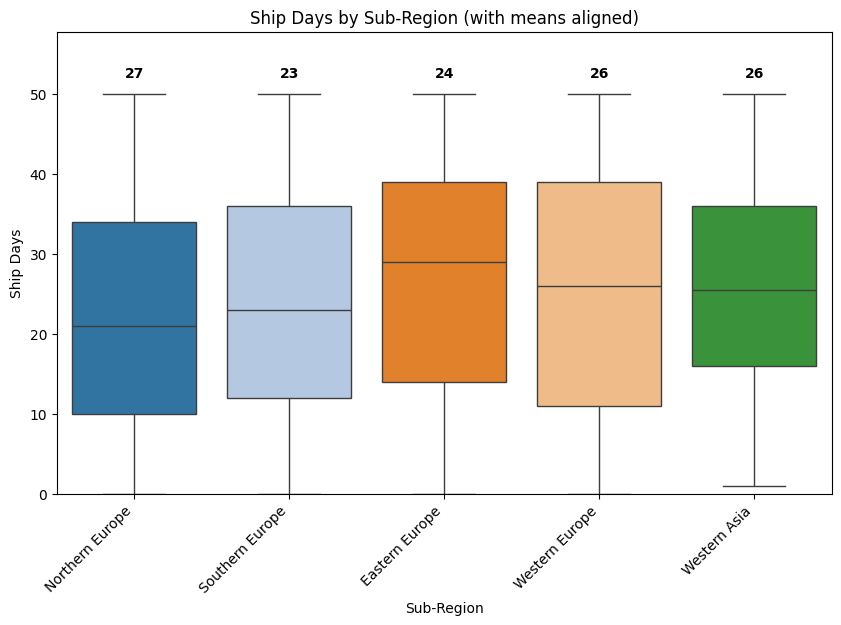

In [ ]:
# Obliczenie liczby dni wysyłki
connected_table['ship_days'] = (connected_table['Ship Date'] - connected_table['Order Date']).dt.days

# Obliczenie średniej liczby dni wysyłki dla każdego subregionu
means = connected_table.groupby('Sub-Region')['ship_days'].mean()
Sub_Region = means.index

# Inicjalizacja wykresu pudełkowego
plt.figure(figsize=(10, 6))
ax = sns.boxplot(data=connected_table, x='Sub-Region', y='ship_days', hue='Sub-Region', palette='tab20', legend=False)

# Ustalenie stałej wysokości dla etykiet tekstowych (5% powyżej maksymalnej wartości)
label_height = connected_table['ship_days'].max() * 1.05

# Pętla dodająca średnie wartości nad każdym pudełkiem (wyrównane w jednej linii)
for i, region in enumerate(Sub_Region):
    mean_val = means[region]
    ax.text(i, label_height, f'{mean_val:.0f}', ha='center', va='center', fontweight='bold')

# Konfiguracja osi, rotacja etykiet i tytuł
plt.xlabel('Sub-Region')
plt.ylabel('Ship Days')
plt.title('Ship Days by Sub-Region (with means aligned)')
plt.xticks(rotation=45, ha='right')

# Zwiększenie limitu osi Y, aby etykiety były widoczne
plt.ylim(0, label_height * 1.1)

# Wyświetlenie wykresu
plt.show()

**Analiza wykresu Ship Days by Sub-Region**
1. Średni czas wysyłki: Średni czas realizacji zamówienia (oznaczony liczbami na wykresie) waha się od 23 do 27 dni w zależności od subregionu.
Najszybciej zamówienia są wysyłane w Northern Europe (średnio 23 dni).
Najdłużej proces ten trwa w Eastern Europe (średnio 27 dni) oraz Western Asia (średnio 26 dni).
2. Rozkład (Boxplot):
W każdym z subregionów rozpiętość czasu wysyłki jest zbliżona – od 0 do 50 dni.
Subregiony Eastern Europe i Western Asia mają nieco wyżej położoną medianę (linia wewnątrz pudełka), co sugeruje, że większy odsetek zamówień w tych rejonach czeka na wysyłkę dłużej niż w Europie Północnej czy Południowej.
3. Stabilność procesu: Podobnie jak w przypadku typów produktów, proces logistyczny wydaje się mieć sztywne ramy (maksymalnie 50 dni). Nie widać tu drastycznych anomalii, co świadczy o spójnej polityce wysyłkowej na wszystkich obsługiwanych rynkach.
4. Wniosek: Różnice między subregionami są niewielkie (maksymalnie 4 dni różnicy w średniej)

The correlation between shipping time and profit: 0.0607


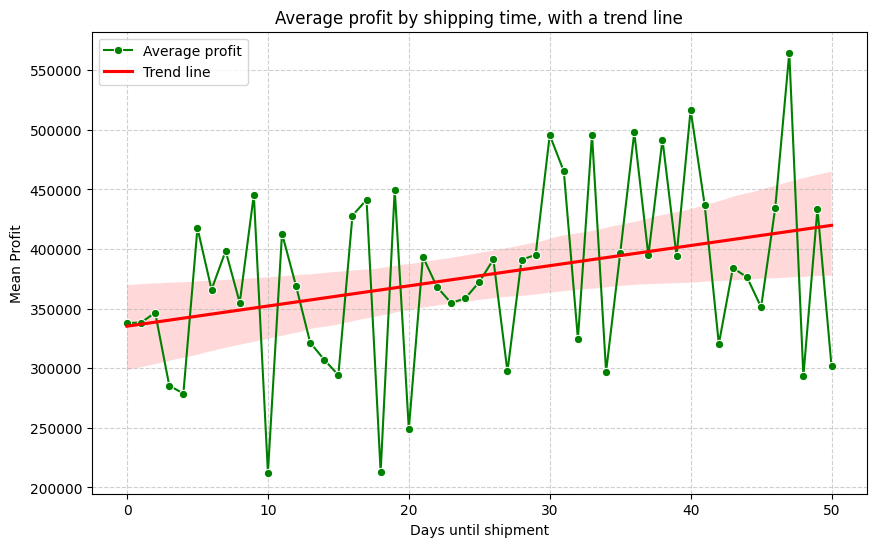

In [ ]:
# Obliczenie liczby dni wysyłki (ponowne upewnienie się co do wartości)
connected_table['ship_days'] = (connected_table['Ship Date'] - connected_table['Order Date']).dt.days

# Obliczenie korelacji Pearsona między czasem wysyłki a zyskiem całkowitym
correlation = connected_table['ship_days'].corr(connected_table['total_profit'])
print(f"The correlation between shipping time and profit: {correlation:.4f}")

# Przygotowanie danych: obliczenie średniego zysku dla każdego konkretnego dnia oczekiwania
plt.figure(figsize=(10, 6))
profit_by_days = connected_table.groupby('ship_days')['total_profit'].mean().reset_index()

# Rysowanie wykresu liniowego pokazującego średni zysk
sns.lineplot(data=profit_by_days, x='ship_days', y='total_profit', marker='o', color='green', label='Average profit')

# Dodanie czerwonej linii trendu (regresji) bez przedziału ufności
sns.regplot(data=profit_by_days, x='ship_days', y='total_profit', scatter=False, color='red', label='Trend line')

# Konfiguracja tytułu, etykiet i legendy
plt.title('Average profit by shipping time, with a trend line')
plt.xlabel('Days until shipment')
plt.ylabel('Mean Profit')
plt.legend()

# Dodanie siatki pomocniczej dla lepszej czytelności
plt.grid(True, linestyle='--', alpha=0.6)

# Wyświetlenie wykresu
plt.show()

**Analiza wykresu Average profit by shipping time, with a trend line**
1. Słaba korelacja: Współczynnik korelacji wynosi ok. 0.06, co oznacza bardzo słabą, niemal nieistniejącą zależność liniową między czasem oczekiwania na wysyłkę a wygenerowanym zyskiem.
2. Linia trendu: Czerwona linia trendu jest niemal płaska (lekko wznosząca), co potwierdza, że wydłużenie czasu wysyłki nie wpływa znacząco na wysokość zysku z pojedynczego zamówienia.
3. Zmienność: Zielona linia wykresu wykazuje duże wahania – np. zauważalny jest nagły skok średniego zysku dla zamówień wysłanych po 47 dniach. Może to wynikać z faktu, że w tej konkretnej grupie znalazło się kilka bardzo dużych i zyskownych zamówień (tzw. wartości odstające).
4. Wniosek: Czas wysyłki jest neutralny dla rentowności. Firma nie zarabia więcej ani mniej na zamówieniach, które są realizowane szybciej lub wolniej. Sugeruje to, że struktura marży jest stała i niezależna od dynamiki procesów logistycznych.

In [ ]:
import plotly.express as px

# Agregacja danych: grupowanie według miesiąca (freq='ME') oraz typu produktu
# Sumowanie liczby sprzedanych jednostek dla każdej grupy
sales_dynamics = connected_table.groupby([pd.Grouper(key='Order Date', freq='ME'), 'Item Type'])['Units Sold'].sum().reset_index()

# Tworzenie interaktywnego wykresu liniowego przy użyciu Plotly Express
fig = px.line(
    sales_dynamics,
    x='Order Date',
    y='Units Sold',
    color='Item Type',
    color_discrete_sequence=px.colors.qualitative.Alphabet, # Ustalenie rozbudowanej palety kolorów
    title='Sales trends by product category',
    labels={'Units Sold': 'Units Sold', 'Order Date': 'Order Date', 'Item Type': 'Item Type'}
)

# Konfiguracja układu wykresu: tytuły osi, legenda oraz tryb najechania myszką (hover)
fig.update_layout(
    xaxis_title='Order Date',
    yaxis_title='Units Sold',
    legend_title='Category',
    hovermode='x unified'
)

# Wyświetlenie interaktywnej wizualizacji
fig.show()
# Żeby wyswietlić wybrane kategorie produktow na wykresie trzeba kliknac w nazwe produktu w legedzie.

### Analiza wykresu 'Sales trends by product category'

Na podstawie interaktywnego wykresu dynamiki sprzedaży dla poszczególnych kategorii produktów można sformułować następujące wnioski:

1. **Wysoka zmienność miesięczna**: Wszystkie kategorie produktów wykazują znaczące wahania sprzedaży z miesiąca na miesiąc. Brak jest jednej kategorii, która utrzymywałaby stały, liniowy wzrost, co sugeruje silny wpływ czynników zewnętrznych lub specyficznych kampanii promocyjnych.
2. **Dominujące kategorie**: Kategorie takie jak **Office Supplies**, **Clothes** oraz **Beverages** często osiągają najwyższe piki sprzedażowe (często przekraczające 40-60 tys. jednostek w pojedynczych miesiącach), co potwierdza ich status liderów wolumenu sprzedaży.
3. **Korelacja między kategoriami**: Można zaobserwować, że w wielu okresach (np. przełomy lat) trendy dla różnych kategorii poruszają się w podobnych kierunkach, co może wskazywać na ogólne trendy rynkowe lub sezonowość zakupową (np. okresy świąteczne lub wyprzedażowe).
4. **Wniosek strategiczny**: Duże skoki sprzedaży w kluczowych kategoriach wymagają elastycznego zarządzania zapasami, aby uniknąć braków magazynowych w okresach szczytowych (piki na wykresie) oraz nadmiarów w okresach nagłych spadków.

In [ ]:
# Agregacja danych: grupowanie według miesiąca oraz regionu i sumowanie Units Sold
sales_dynamics_region = connected_table.groupby([pd.Grouper(key='Order Date', freq='ME'), 'Region'])['Units Sold'].sum().reset_index()

# Tworzenie interaktywnego wykresu liniowego dla regionów przy użyciu Plotly Express
fig = px.line(
    sales_dynamics_region,
    x='Order Date',
    y='Units Sold',
    color='Region',
    title='Sales trends by Region',
    labels={'Units Sold': 'Units Sold', 'Order Date': 'Order Date', 'Region': 'Region'}
)

# Konfiguracja układu: tytuły osi, legenda oraz ujednolicony tryb podpowiedzi (hover)
fig.update_layout(
    xaxis_title='Order Date',
    yaxis_title='Units Sold',
    legend_title='Region',
    hovermode='x unified'
)

# Wyświetlenie wykresu
fig.show()

**Analiza wykresu Sales trends by Region**
1. Dominacja Europy: Wykres wyraźnie pokazuje, że Europa jest głównym rynkiem zbytu. Wolumen sprzedaży w tym regionie jest wielokrotnie wyższy niż w Azji w całym badanym okresie.
3. Sezonowość i zmienność: Sprzedaż w Europie charakteryzuje się dużą zmiennością z wyraźnymi pikami (np. początek 2010 r., kiedy sprzedaż przekroczyła 93 tys. jednostek) oraz okresowymi spadkami. Sugeruje to silną sezonowość popytu na tym rynku.
3. Rynek Azjatycki: Sprzedaż w Azji jest znacznie bardziej stabilna, ale utrzymuje się na niskim poziomie (zazwyczaj w przedziale 10-20 tys. jednostek). Nie widać tu tak gwałtownych skoków jak w przypadku Europy.
3. Trendy długoterminowe: Pomimo wahań, ogólny trend dla Europy wydaje się stabilny z tendencją do powracania do wysokich poziomów sprzedaży. W Azji trend jest płaski, co wskazuje na stały, niszowy popyt.
4. Wniosek: Wyniki firmy są silnie uzależnione od kondycji rynku europejskiego.

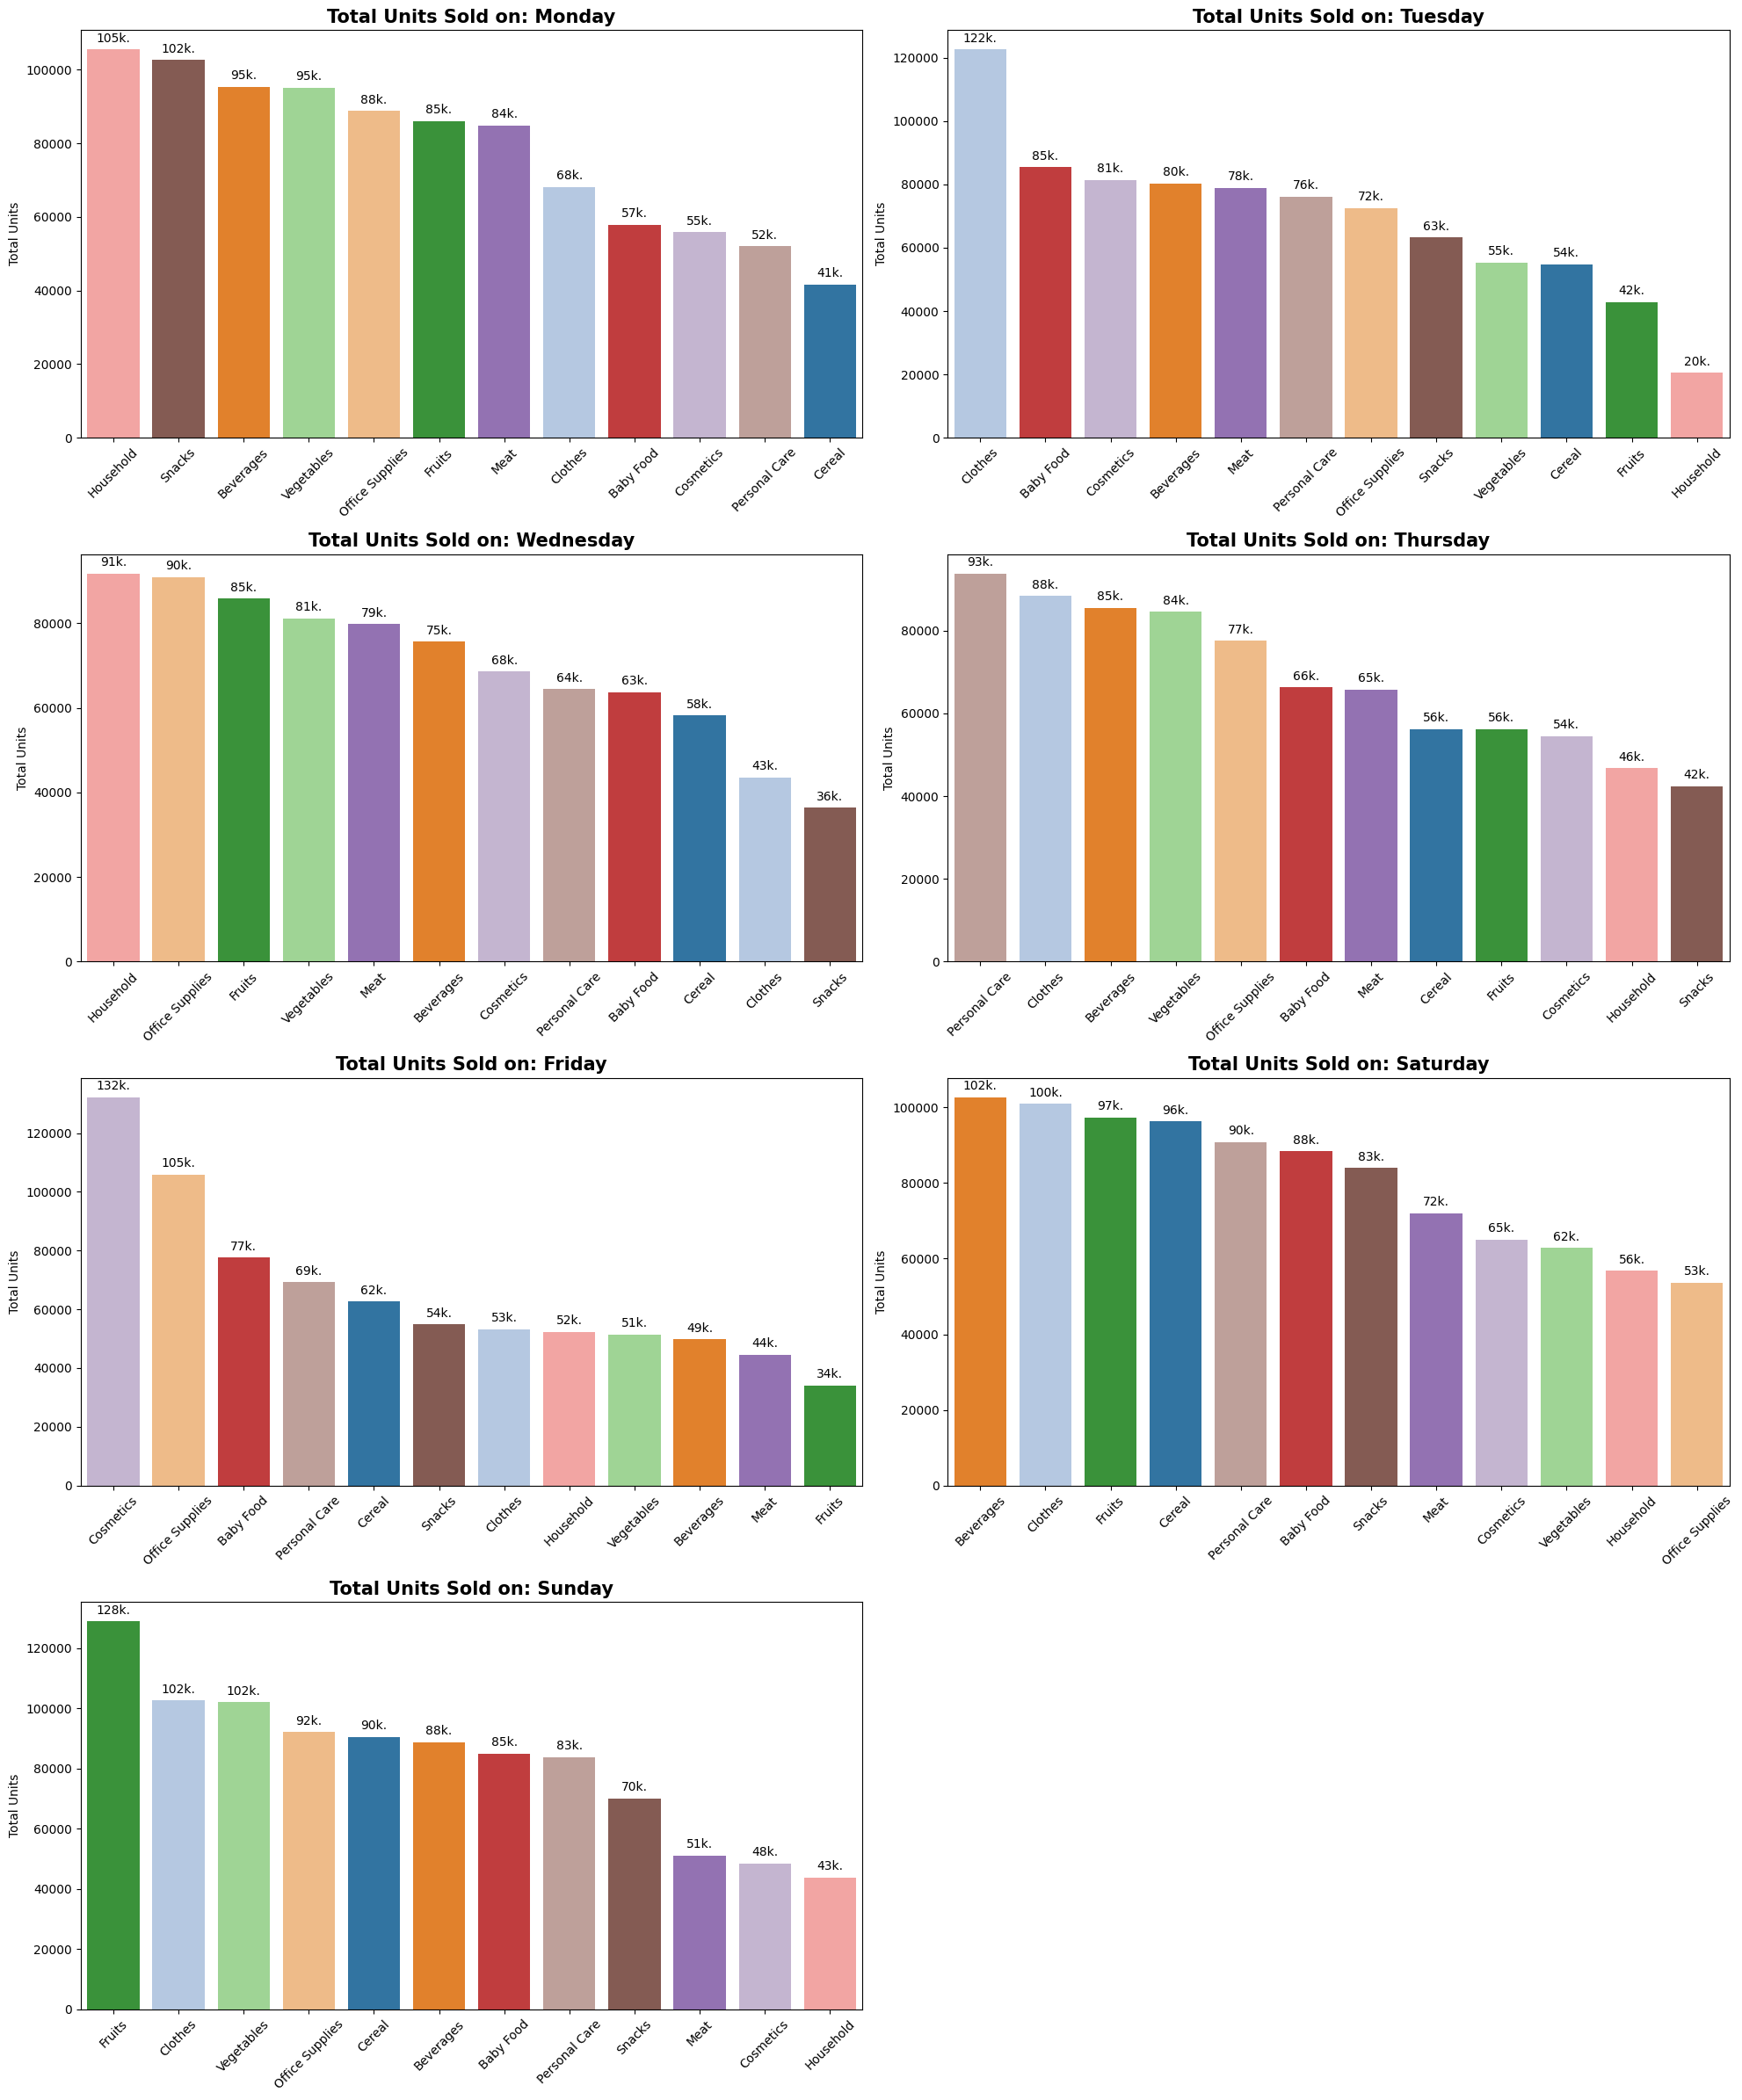

In [ ]:
# Wyciągnięcie nazwy dnia tygodnia z daty zamówienia
connected_table['Order Day'] = pd.to_datetime(connected_table['Order Date']).dt.day_name()

# Ustalenie poprawnej kolejności dni tygodnia
days_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
connected_table['Order Day'] = pd.Categorical(connected_table['Order Day'], categories=days_order, ordered=True)

# Agregacja sumy sprzedanych jednostek według dnia i typu produktu
sales_sum_by_day = connected_table.groupby(['Order Day', 'Item Type'], observed=False)['Units Sold'].sum().reset_index()

# Przygotowanie palety kolorów dla każdego unikalnego produktu
unique_products = connected_table['Item Type'].unique()
product_palette = dict(zip(unique_products, sns.color_palette("tab20", len(unique_products))))

# Tworzenie siatki wykresów (4 wiersze, 2 kolumny)
fig, axes = plt.subplots(nrows=4, ncols=2, figsize=(20, 24))
axes = axes.flatten()

for i, day in enumerate(days_order):
    # Filtrowanie danych dla konkretnego dnia i sortowanie malejąco
    day_data = sales_sum_by_day[sales_sum_by_day['Order Day'] == day].sort_values('Units Sold', ascending=False)

    # Rysowanie wykresu słupkowego na odpowiednim podwykresie
    sns.barplot(
        data=day_data,
        x='Item Type',
        y='Units Sold',
        ax=axes[i],
        hue='Item Type',
        palette=product_palette,
        legend=False
    )

    # Dodawanie adnotacji tekstowych (wartości w tysiącach 'k') nad słupkami
    for p in axes[i].patches:
        if p.get_height() > 0:
            axes[i].annotate(f'{int(p.get_height()/1000)}k.',
                             (p.get_x() + p.get_width() / 2., p.get_height()),
                             ha='center', va='center',
                             xytext=(0, 9),
                             textcoords='offset points',
                             fontsize=10)

    # Formatowanie tytułów i osi
    axes[i].set_title(f'Total Units Sold on: {day}', fontsize=15, fontweight='bold')
    axes[i].tick_params(axis='x', rotation=45)
    axes[i].set_xlabel('')
    axes[i].set_ylabel('Total Units')

# Usunięcie pustego ósmego wykresu (mamy 7 dni tygodnia)
fig.delaxes(axes[7])

plt.tight_layout()
plt.show()

**Analiza wykresu Total Units Sold on day**
1. Poniedziałek (Monday): Zdecydowanym liderem jest Household, a zaraz za nim plasuje się kategoria Snacks. To dzień o bardzo wysokim wolumenie dla artykułów domowych.
2. Wtorek (Tuesday): Tutaj na pierwsze miejsce wysuwają się Cosmetics (Kosmetyki), osiągając najwyższy słupek dnia.
3. Środa (Wednesday): Najwięcej sztuk sprzedaje się w kategorii Household (Owoce) oraz Office Supplies.
4. Czwartek (Thursday): Dzień zdominowany przez Personal Care  oraz Clothes.
5. Piątek (Friday): Ponownie najwyższe wyniki notują Cosmetics oraz Office Supplies.
6. Sobota (Saturday): Liderami są Beverages oraz Clothes.
7. Niedziela (Sunday): Najwyższy pik sprzedaży w całym tygodniu należy do kategorii Fruits (blisko 130 tys. sztuk).
8. **Wniosek**: Profil sprzedaży zmienia się drastycznie każdego dnia. Kategorie spożywcze są najbardziej popularne praktycznie kazdego dnia jakaś kategoria sporzywcza zajmuje jedno z pierwszych trzech miejsc z największą ilością sprzedanych produktów .